In [25]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


# E-Commerce Sales Data Analysis

## Project Overview

The objective of this project is to analyze online retail transaction data and identify meaningful business insights.

## Objectives
- Analyze overall sales and revenue.
- Identify top-selling products.
- Understand customer purchasing behavior.
- Analyze country-wise sales performance.
- Identify monthly and seasonal sales trends.
- Visualize business insights.

## Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- SQL
- Power BI

## Dataset
UCI Online Retail Dataset

In [26]:
# Load the dataset

df = pd.read_excel("../data/Online Retail.xlsx")

# Display first 5 rows
df.head()

FileNotFoundError: [Errno 2] No such file or directory: '../data/Online Retail.xlsx'

In [ ]:
import os

print("Current folder:", os.getcwd())
print("\nFiles and folders:")
print(os.listdir("../"))

In [ ]:
import os

print(os.listdir("../data"))

In [ ]:
# Load the dataset

df = pd.read_excel("../data/online_retail.xlsx..xlsx")

# Display first 5 rows
df.head()

In [ ]:
print("Jupyter is working!")

In [ ]:
# Dataset Information

print("Dataset Information")

# Number of rows and columns
print("\nDataset Shape:")
print(df.shape)

# Column names
print("\nColumn Names:")
print(df.columns)

# Dataset information
print("\nDataset Info:")
df.info()

In [ ]:
df.describe()

In [ ]:
# Check missing values in each column

missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

print("\nMissing Values Percentage:")

missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage.round(2))

In [ ]:
# Check duplicate records

duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

In [ ]:
# Create a copy of the original dataset

df_clean = df.copy()

print("Original Dataset Shape:", df.shape)
print("Copied Dataset Shape:", df_clean.shape)

In [ ]:
# Remove duplicate records

df_clean = df_clean.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df_clean.shape)

print("Remaining Duplicate Records:", df_clean.duplicated().sum())

In [ ]:
# Remove rows with missing product descriptions
df_clean = df_clean.dropna(subset=['Description'])

# Check missing values again
print("Dataset Shape After Removing Missing Descriptions:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

In [ ]:
# Count cancelled invoices
cancelled_orders = df_clean[
    df_clean['InvoiceNo'].astype(str).str.startswith('C')
]

print("Total Cancelled Order Records:", len(cancelled_orders))

In [ ]:
# Count records with negative quantities
negative_quantity = df_clean[df_clean['Quantity'] < 0]

print("Records with Negative Quantity:", len(negative_quantity))

In [ ]:
# Check zero and negative unit prices

zero_prices = (df_clean['UnitPrice'] == 0).sum()
negative_prices = (df_clean['UnitPrice'] < 0).sum()

print("Records with Zero Unit Price:", zero_prices)
print("Records with Negative Unit Price:", negative_prices)

In [ ]:
# Display records with zero or negative unit prices

unusual_prices = df_clean[df_clean['UnitPrice'] <= 0]

unusual_prices.head(10)

In [ ]:
# Create a dataset containing completed sales only

df_sales = df_clean[
    (~df_clean['InvoiceNo'].astype(str).str.startswith('C')) &
    (df_clean['Quantity'] > 0) &
    (df_clean['UnitPrice'] > 0)
].copy()

print("Original Cleaned Dataset Shape:", df_clean.shape)
print("Sales Dataset Shape:", df_sales.shape)

In [ ]:
# Calculate total sales for each transaction

df_sales['TotalPrice'] = df_sales['Quantity'] * df_sales['UnitPrice']

# Display first 5 records
df_sales.head()

In [ ]:
# Calculate overall revenue

total_revenue = df_sales['TotalPrice'].sum()

print("Total Revenue: £", round(total_revenue, 2))

## Initial Sales Findings

- Total Revenue: £10,642,110.80
- Completed Sales Records: 524,878

In [ ]:
# Calculate number of unique orders
total_orders = df_sales['InvoiceNo'].nunique()

# Calculate Average Order Value
average_order_value = total_revenue / total_orders

print("Total Orders:", total_orders)
print("Average Order Value: £", round(average_order_value, 2))

- Total Orders: 19,960
- Average Order Value (AOV): £533.17

In [ ]:
# Find top 10 best-selling products

top_products = (
    df_sales.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Best-Selling Products:")
print(top_products)

## Top 10 Best-Selling Products

The top-selling product is PAPER CRAFT, LITTLE BIRDIE, with 80,995 units sold.

The analysis identifies the 10 products with the highest total quantities sold.

In [ ]:
# Visualize top 10 best-selling products

plt.figure(figsize=(12, 6))

top_products.sort_values().plot(kind='barh')

plt.title('Top 10 Best-Selling Products')
plt.xlabel('Quantity Sold')
plt.ylabel('Product Name')

plt.tight_layout()
plt.show()

### Top Products Visualization

A horizontal bar chart was created to visualize the top 10 best-selling products based on total quantity sold.

The chart helps identify the most popular products among customers.

In [ ]:
# Calculate country-wise revenue

country_sales = (
    df_sales.groupby('Country')['TotalPrice']
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Countries by Revenue:")
print(country_sales.head(10))

## Country-wise Sales Analysis

- The United Kingdom generated the highest revenue.
- Netherlands ranked second.
- EIRE ranked third.
- The United Kingdom is the major revenue-generating market in this dataset.

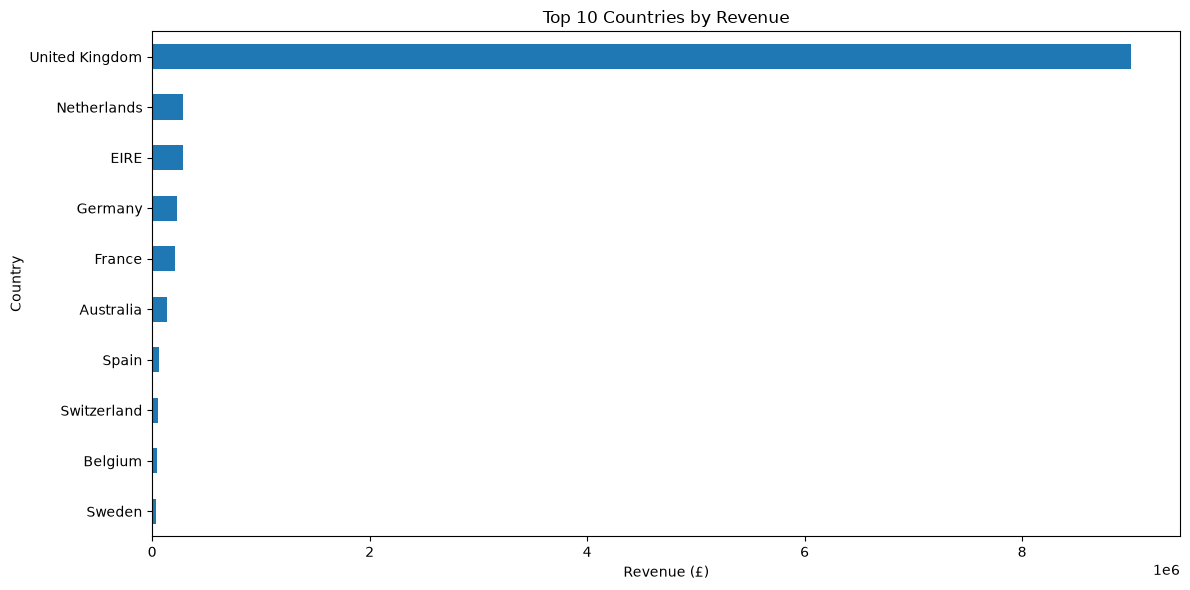

In [27]:
# Visualize top 10 countries by revenue

top_countries = country_sales.head(10)

plt.figure(figsize=(12, 6))

top_countries.sort_values().plot(kind='barh')

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

### Country-wise Revenue Visualization

A horizontal bar chart was created to compare revenue across the top 10 countries.

The United Kingdom contributes the highest revenue compared with other countries.

In [29]:
# Extract month and year from InvoiceDate

df_sales['YearMonth'] = df_sales['InvoiceDate'].dt.to_period('M')

# Calculate monthly revenue

monthly_sales = df_sales.groupby('YearMonth')['TotalPrice'].sum()

print("Monthly Revenue:")
print(monthly_sales)

Monthly Revenue:
YearMonth
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: TotalPrice, dtype: float64


## Monthly Sales Analysis

- The highest revenue was recorded in November 2011 (£1,503,866.78).
- October 2011 generated £1,151,263.73.
- September 2011 generated £1,056,435.19.
- February 2011 recorded the lowest revenue (£522,545.56).

The business experienced a significant increase in revenue during September, October and November 2011.

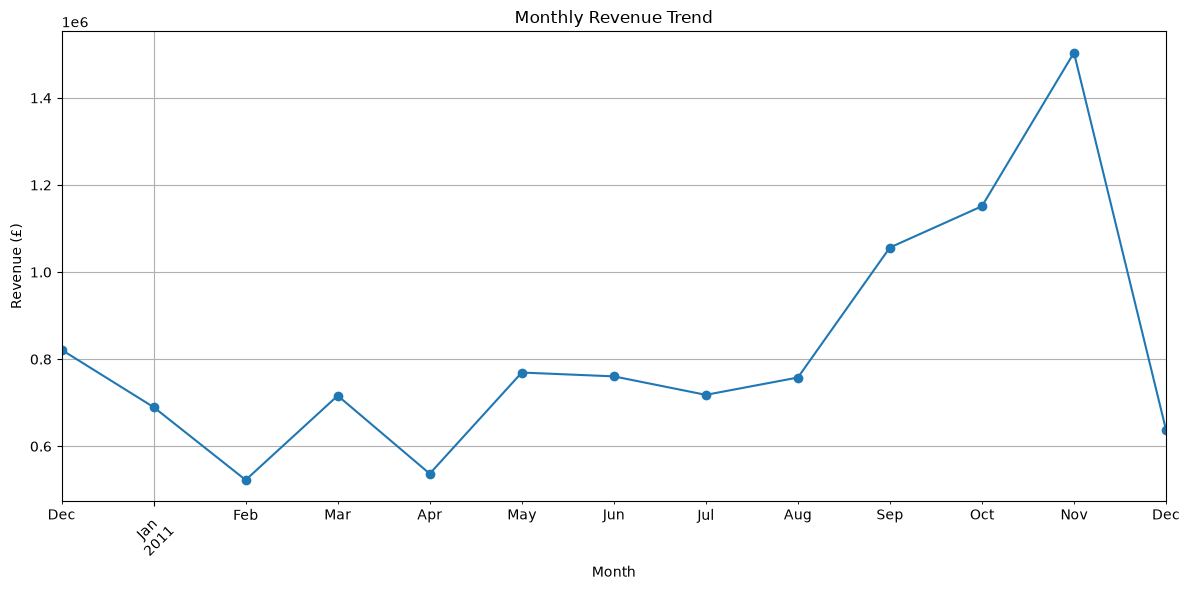

In [30]:
# Visualize monthly revenue

plt.figure(figsize=(12, 6))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

### Monthly Revenue Visualization

A line chart was created to show monthly revenue trends from December 2010 to December 2011.

The chart highlights the increase in revenue during September, October and November 2011, with November recording the highest revenue.

In [31]:
# Calculate total spending by each customer

customer_sales = (
    df_sales.dropna(subset=['CustomerID'])
    .groupby('CustomerID')['TotalPrice']
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Customers by Revenue:")
print(customer_sales.head(10))

Top 10 Customers by Revenue:
CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: TotalPrice, dtype: float64


## Customer Purchasing Behaviour

- Customer ID 14646 was the highest-spending customer, with £280,206.02 in purchases.
- Customer ID 18102 ranked second.
- Customer ID 17450 ranked third.

The analysis identifies the top 10 customers based on their total spending.

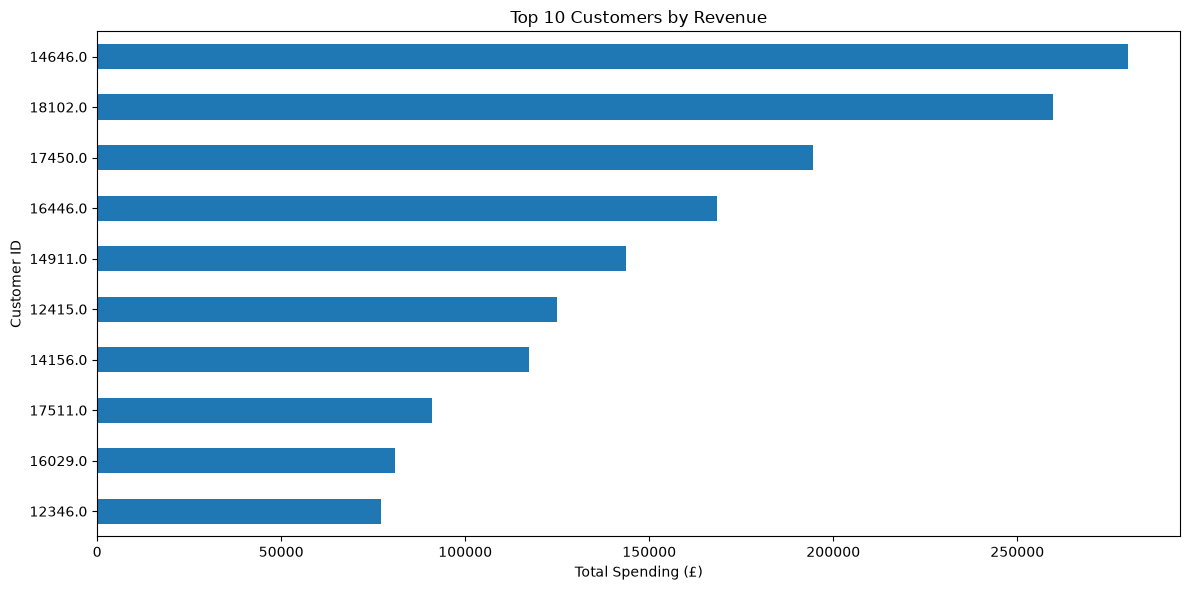

In [32]:
# Visualize top 10 customers by spending

top_customers = customer_sales.head(10)

plt.figure(figsize=(12, 6))

top_customers.sort_values().plot(kind='barh')

plt.title('Top 10 Customers by Revenue')
plt.xlabel('Total Spending (£)')
plt.ylabel('Customer ID')

plt.tight_layout()
plt.show()

### Customer Spending Visualization

A horizontal bar chart was created to compare the total spending of the top 10 customers.

Customer ID 14646 recorded the highest spending among all identified customers.

In [33]:
# Calculate basic quantity statistics

print("Total Quantity Sold:", df_sales['Quantity'].sum())
print("Average Quantity per Transaction:", round(df_sales['Quantity'].mean(), 2))
print("Maximum Quantity in One Transaction:", df_sales['Quantity'].max())
print("Minimum Quantity in One Transaction:", df_sales['Quantity'].min())

Total Quantity Sold: 5572420
Average Quantity per Transaction: 10.62
Maximum Quantity in One Transaction: 80995
Minimum Quantity in One Transaction: 1


## Quantity Analysis

- Total Quantity Sold: 5,572,420 units.
- Average Quantity per Transaction: 10.62 units.
- Maximum Quantity in One Transaction: 80,995 units.
- Minimum Quantity in One Transaction: 1 unit.

The analysis shows that the average transaction contains approximately 11 units.

In [34]:
# Calculate revenue generated by each product

product_revenue = (
    df_sales.groupby('Description')['TotalPrice']
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Products by Revenue:")
print(product_revenue.head(10))

Top 10 Products by Revenue:
Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: TotalPrice, dtype: float64


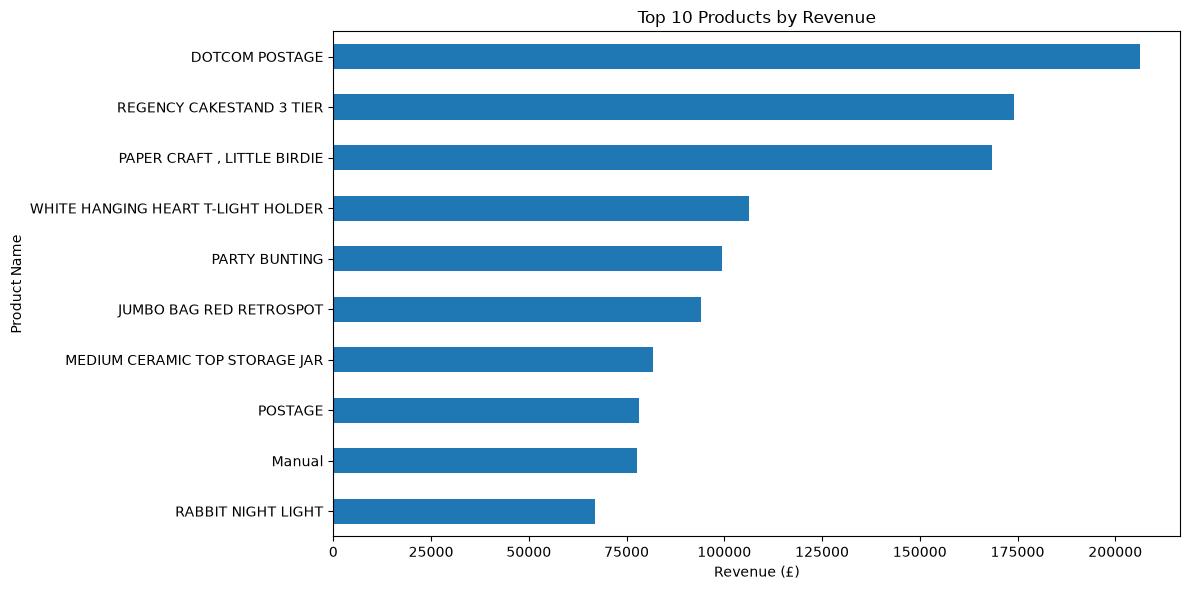

In [35]:
top_revenue_products = product_revenue.head(10)

plt.figure(figsize=(12, 6))

top_revenue_products.sort_values().plot(kind='barh')

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Product Name')

plt.tight_layout()
plt.show()

### Top 10 Products by Revenue

- DOTCOM POSTAGE generated the highest revenue of £206,248.77.
- REGENCY CAKESTAND 3 TIER ranked second with £174,156.54.
- PAPER CRAFT, LITTLE BIRDIE ranked third with £168,469.60.
- Products with the highest sales quantity are not necessarily the highest revenue generators.
- Postage and manual entries also appear among the top revenue contributors.

In [36]:
# Extract day of the week from InvoiceDate

df_sales['DayOfWeek'] = df_sales['InvoiceDate'].dt.day_name()

# Calculate revenue for each day

daily_sales = (
    df_sales.groupby('DayOfWeek')['TotalPrice']
    .sum()
)

# Display revenue by day

print("Revenue by Day of the Week:")
print(daily_sales)

Revenue by Day of the Week:
DayOfWeek
Friday       1837470.491
Monday       1775782.071
Sunday        806790.781
Thursday     2199292.570
Tuesday      2175700.511
Wednesday    1847074.380
Name: TotalPrice, dtype: float64


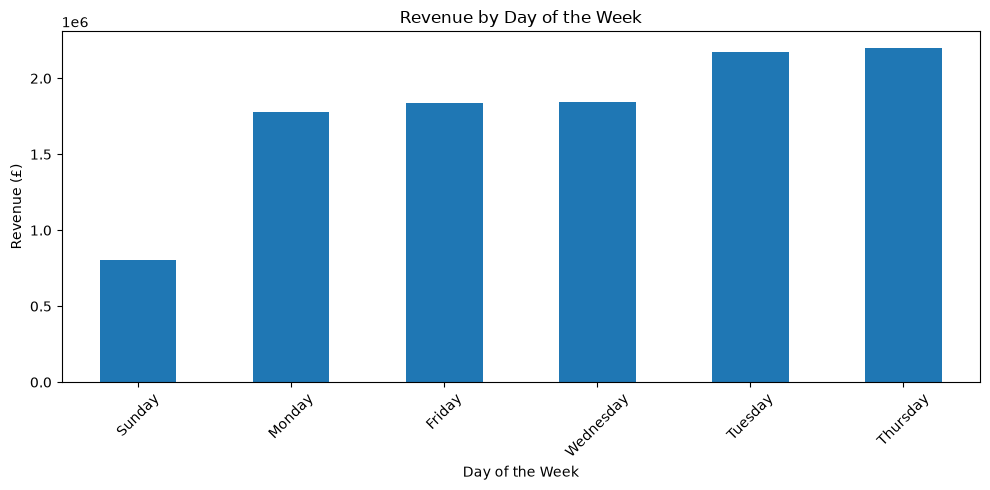

In [37]:
plt.figure(figsize=(10, 5))

daily_sales.sort_values().plot(kind='bar')

plt.title('Revenue by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Day-wise Revenue Analysis

- Thursday generated the highest revenue of £2,199,292.57.
- Tuesday ranked second with £2,175,700.51.
- Sunday recorded the lowest revenue of £806,790.78.
- No transactions were recorded on Saturday in this dataset.
- Thursday and Tuesday were the strongest revenue-generating days.

In [38]:
# Extract the hour from InvoiceDate

df_sales['Hour'] = df_sales['InvoiceDate'].dt.hour

# Calculate revenue by hour

hourly_sales = df_sales.groupby('Hour')['TotalPrice'].sum()

print("Revenue by Hour:")
print(hourly_sales)

Revenue by Hour:
Hour
6           4.250
7       31059.210
8      283750.680
9      990054.991
10    1444814.771
11    1236573.290
12    1439324.660
13    1261195.200
14    1177907.521
15    1350333.310
16     752487.960
17     460963.921
18     144603.610
19      50204.950
20      18832.480
Name: TotalPrice, dtype: float64


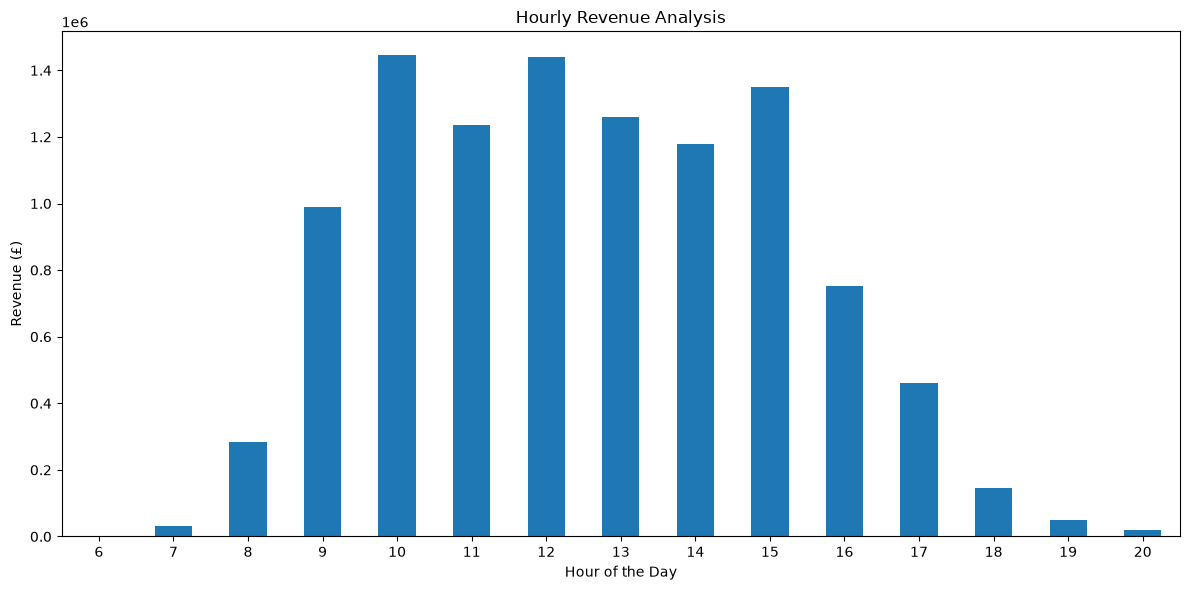

In [39]:
plt.figure(figsize=(12, 6))

hourly_sales.plot(kind='bar')

plt.title('Hourly Revenue Analysis')
plt.xlabel('Hour of the Day')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Hourly Revenue Analysis

- 10 AM generated the highest revenue of £1,444,814.77.
- 12 PM ranked second with £1,439,324.66.
- 3 PM also recorded strong revenue of £1,350,333.31.
- Revenue was generally higher during daytime hours.
- Evening hours recorded comparatively lower revenue.

In [40]:
# Calculate the number of orders placed by each customer

customer_orders = (
    df_sales.dropna(subset=['CustomerID'])
    .groupby('CustomerID')['InvoiceNo']
    .nunique()
    .sort_values(ascending=False)
)

# Display the top 10 customers by number of orders

print("Top 10 Customers by Purchase Frequency:")
print(customer_orders.head(10))

Top 10 Customers by Purchase Frequency:
CustomerID
12748.0    209
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     73
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64


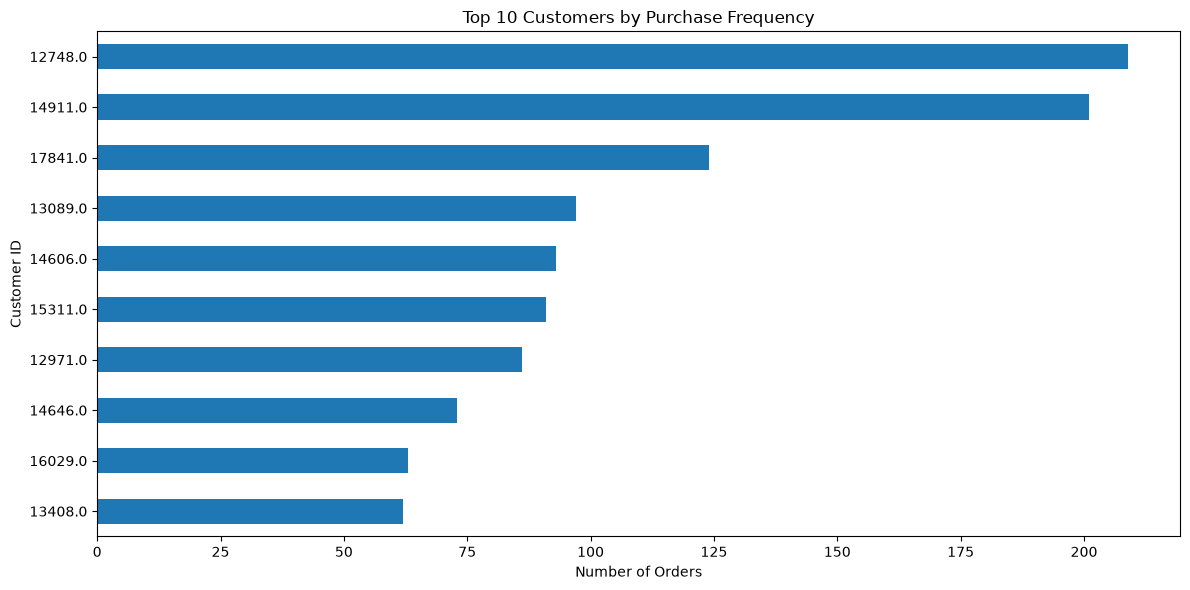

In [41]:
top_frequent_customers = customer_orders.head(10)

plt.figure(figsize=(12, 6))

top_frequent_customers.sort_values().plot(kind='barh')

plt.title('Top 10 Customers by Purchase Frequency')
plt.xlabel('Number of Orders')
plt.ylabel('Customer ID')

plt.tight_layout()
plt.show()

### Customer Purchase Frequency Analysis

- Customer 12748 placed the highest number of orders (209).
- Customer 14911 ranked second with 201 orders.
- Customer 17841 placed 124 orders.
- Frequent purchasing customers contribute to repeat business.
- The customer with the highest purchase frequency is not necessarily the highest-spending customer.

In [42]:
# Calculate the number of orders from each country

country_orders = (
    df_sales.groupby('Country')['InvoiceNo']
    .nunique()
    .sort_values(ascending=False)
)

# Display the top 10 countries

print("Top 10 Countries by Number of Orders:")
print(country_orders.head(10))

Top 10 Countries by Number of Orders:
Country
United Kingdom    18019
Germany             457
France              392
EIRE                288
Belgium              98
Netherlands          94
Spain                90
Portugal             58
Australia            57
Switzerland          54
Name: InvoiceNo, dtype: int64


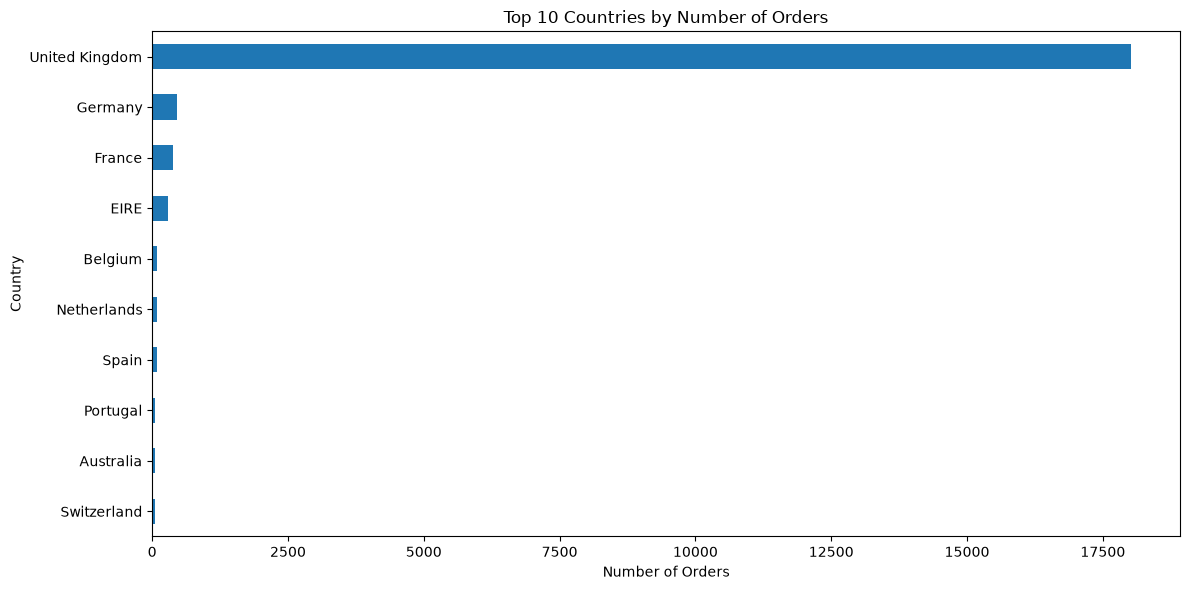

In [43]:
top_country_orders = country_orders.head(10)

plt.figure(figsize=(12, 6))

top_country_orders.sort_values().plot(kind='barh')

plt.title('Top 10 Countries by Number of Orders')
plt.xlabel('Number of Orders')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

### Country-wise Order Analysis

- United Kingdom recorded the highest number of orders (18,019).
- Germany ranked second with 457 orders.
- France ranked third with 392 orders.
- The United Kingdom dominates the order volume in this dataset.
- Other European countries also contribute to the business.

In [44]:
# Calculate average order value by country

country_aov = (
    df_sales.groupby('Country')
    .apply(lambda x: x['TotalPrice'].sum() / x['InvoiceNo'].nunique())
    .sort_values(ascending=False)
)

print("Top 10 Countries by Average Order Value:")
print(country_aov.head(10).round(2))

Top 10 Countries by Average Order Value:
Country
Singapore      3039.90
Netherlands    3036.66
Australia      2429.01
Japan          1969.28
Lebanon        1693.88
Hong Kong      1407.55
Brazil         1143.60
Sweden         1065.77
Switzerland    1056.81
Denmark        1053.07
dtype: float64


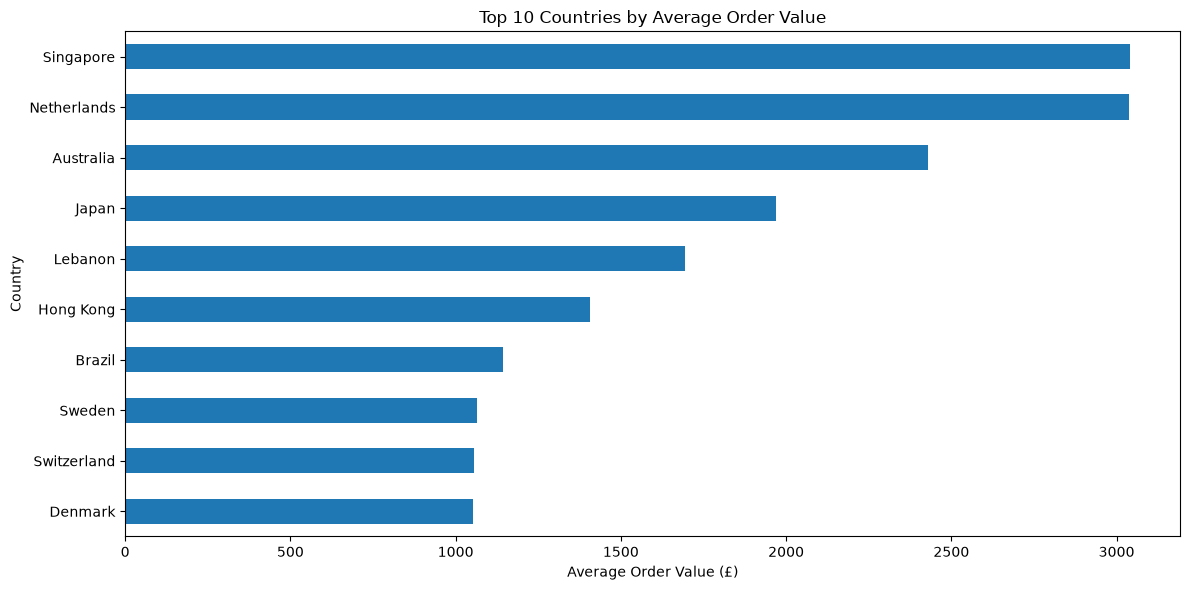

In [45]:
top_country_aov = country_aov.head(10)

plt.figure(figsize=(12, 6))

top_country_aov.sort_values().plot(kind='barh')

plt.title('Top 10 Countries by Average Order Value')
plt.xlabel('Average Order Value (£)')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

### Average Order Value by Country

- Singapore recorded the highest average order value of £3,039.90.
- Netherlands ranked second with £3,036.66.
- Australia ranked third with £2,429.01.
- Countries with fewer orders can generate higher average spending per order.
- The country with the highest total revenue is not necessarily the country with the highest average order value.

In [46]:
# Calculate total spending for each customer

customer_spending = (
    df_sales.dropna(subset=['CustomerID'])
    .groupby('CustomerID')['TotalPrice']
    .sum()
)

# Calculate spending categories

customer_segments = pd.cut(
    customer_spending,
    bins=[0, 500, 2000, float('inf')],
    labels=['Low Value', 'Medium Value', 'High Value']
)

# Count customers in each category

print("Customer Segmentation:")
print(customer_segments.value_counts())

Customer Segmentation:
TotalPrice
Low Value       1765
Medium Value    1677
High Value       896
Name: count, dtype: int64


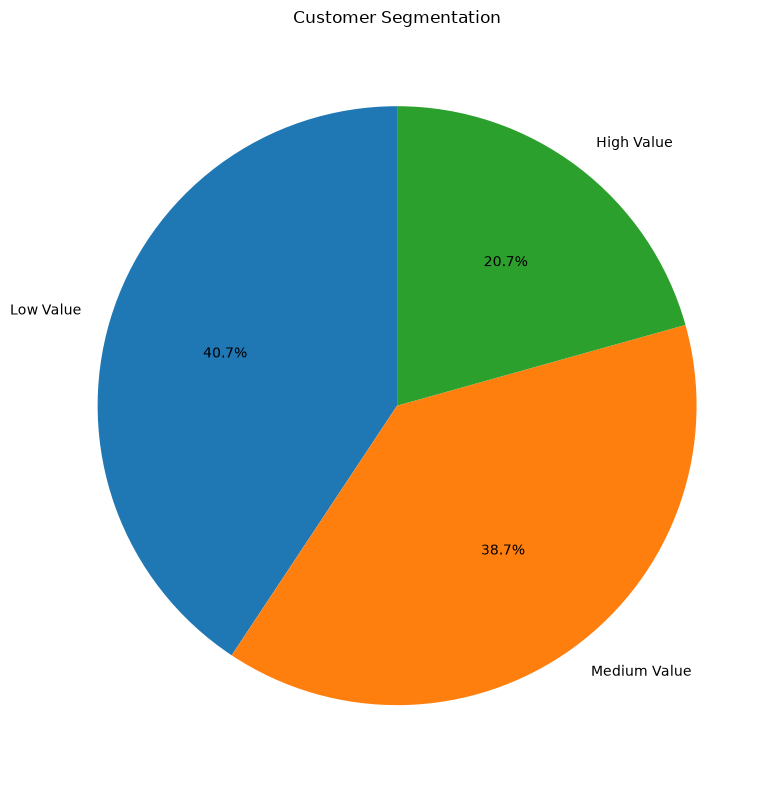

In [47]:
segment_counts = customer_segments.value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    segment_counts,
    labels=segment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Segmentation')

plt.tight_layout()
plt.show()

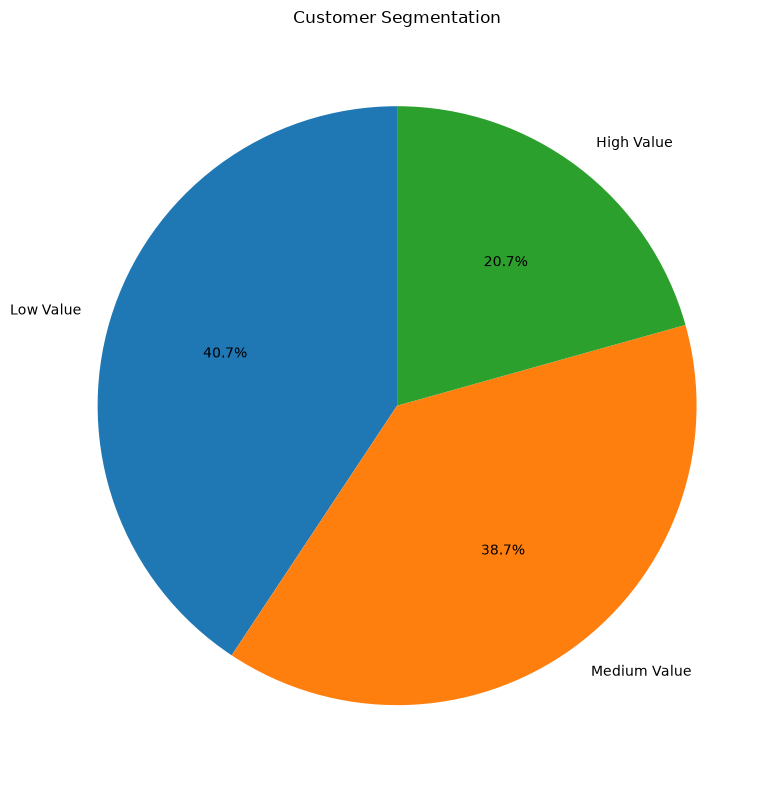

In [48]:
segment_counts = customer_segments.value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    segment_counts,
    labels=segment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Segmentation')

plt.tight_layout()
plt.show()

### Customer Segmentation Analysis

- 1,765 customers belong to the Low Value segment.
- 1,677 customers belong to the Medium Value segment.
- 896 customers belong to the High Value segment.
- Low Value customers represent the largest customer segment.
- High Value customers represent the smallest customer segment.
- Customer segmentation helps businesses identify different spending groups.

In [49]:
# Calculate the number of unique orders each month

monthly_orders = (
    df_sales.groupby('YearMonth')['InvoiceNo']
    .nunique()
)

print("Monthly Order Count:")
print(monthly_orders)

Monthly Order Count:
YearMonth
2010-12    1559
2011-01    1086
2011-02    1100
2011-03    1454
2011-04    1246
2011-05    1681
2011-06    1533
2011-07    1475
2011-08    1361
2011-09    1837
2011-10    2040
2011-11    2769
2011-12     819
Freq: M, Name: InvoiceNo, dtype: int64


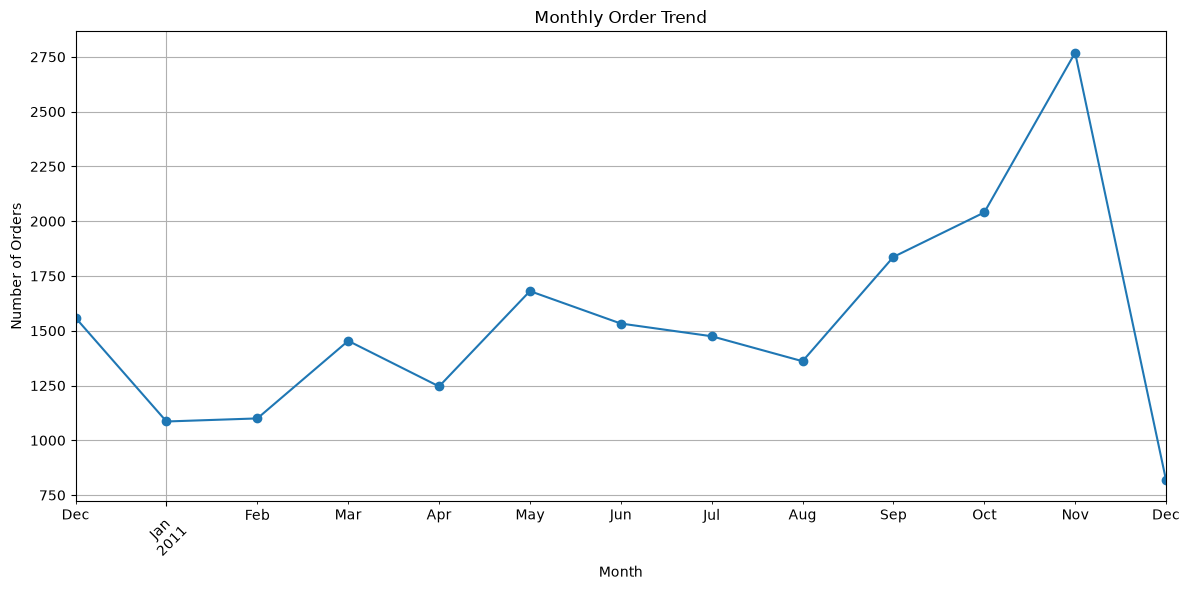

In [50]:
plt.figure(figsize=(12, 6))

monthly_orders.plot(kind='line', marker='o')

plt.title('Monthly Order Trend')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

### Monthly Order Analysis

- November 2011 recorded the highest number of orders (2,769).
- October 2011 ranked second with 2,040 orders.
- September 2011 recorded 1,837 orders.
- December 2011 had the lowest number of orders (819).
- Order activity increased significantly between September and November.

In [51]:
# Identify cancelled invoices

cancelled_orders = df_clean[
    df_clean['InvoiceNo'].astype(str).str.startswith('C')
]

# Count unique cancelled orders

total_cancelled_orders = cancelled_orders['InvoiceNo'].nunique()

print("Total Cancelled Orders:", total_cancelled_orders)

Total Cancelled Orders: 3836


In [52]:
total_orders_before_cleaning = df_clean['InvoiceNo'].nunique()

cancellation_rate = (
    total_cancelled_orders / total_orders_before_cleaning
) * 100

print("Cancellation Rate:", round(cancellation_rate, 2), "%")

Cancellation Rate: 15.69 %


### Order Cancellation Analysis

- A total of 3,836 unique orders were cancelled.
- The cancellation rate was 15.69%.
- Cancelled orders represent approximately 16% of the unique invoices in the cleaned dataset.

In [53]:
returned_records = df_clean[df_clean['Quantity'] < 0]

print("Total Returned Records:", len(returned_records))
print("Total Returned Quantity:", abs(returned_records['Quantity'].sum()))

Total Returned Records: 9725
Total Returned Quantity: 436361


### Product Returns Analysis

- A total of 9,725 records contained negative quantities.
- The total quantity recorded as returned was 436,361 units.
- Negative quantities may represent product returns or transaction adjustments.

In [54]:
returned_value = (
    returned_records['Quantity'] * returned_records['UnitPrice']
).sum()

print("Total Return Value: £", round(abs(returned_value), 2))

Total Return Value: £ 893979.73


- The total value associated with negative-quantity transactions was £893,979.73.

In [55]:
df_clean['TransactionValue'] = (
    df_clean['Quantity'] * df_clean['UnitPrice']
)

net_revenue = df_clean['TransactionValue'].sum()

print("Net Transaction Revenue: £", round(net_revenue, 2))

Net Transaction Revenue: £ 9726006.95


### Net Revenue Analysis

- Completed sales generated £10,642,110.80 in revenue.
- Transactions with negative quantities had an absolute value of £893,979.73.
- Net transaction revenue across the cleaned dataset was £9,726,006.95.

In [57]:
df_sales.to_csv("../data/cleaned_sales.csv", index=False)

In [58]:
import os

print(os.path.exists("../data/cleaned_sales.csv"))

True


In [60]:
import mysql.connector

connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password="",
    database="ecommerce_analysis"
)

print("MySQL connected successfully!")

MySQL connected successfully!


In [61]:
import pandas as pd

df_sql = pd.read_csv("../data/cleaned_sales.csv")

print(df_sql.shape)
print(df_sql.head())

(524878, 12)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

           InvoiceDate  UnitPrice  CustomerID         Country  TotalPrice  \
0  2010-12-01 08:26:00       2.55     17850.0  United Kingdom       15.30   
1  2010-12-01 08:26:00       3.39     17850.0  United Kingdom       20.34   
2  2010-12-01 08:26:00       2.75     17850.0  United Kingdom       22.00   
3  2010-12-01 08:26:00       3.39     17850.0  United Kingdom       20.34   
4  2010-12-01 08:26:00       3.39     17850.0  United Kingdom       20.34   

  YearMonth  DayOfWeek  Hour  
0   2010-12  Wednesday     8  
1   2010-12  Wednesday     8 

In [62]:
cursor = connection.cursor()

cursor.execute("SELECT COUNT(*) FROM sales")

print("Current rows in MySQL:", cursor.fetchone()[0])

Current rows in MySQL: 0


In [63]:
import numpy as np

insert_query = """
INSERT INTO sales (
    InvoiceNo, StockCode, Description, Quantity,
    InvoiceDate, UnitPrice, CustomerID, Country,
    TotalPrice, YearMonth, DayOfWeek, Hour
)
VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s)
"""

df_insert = df_sql.replace({np.nan: None})

data = list(df_insert.itertuples(index=False, name=None))

batch_size = 1000

for start in range(0, len(data), batch_size):
    batch = data[start:start + batch_size]
    cursor.executemany(insert_query, batch)
    connection.commit()

print("Data inserted successfully!")

Data inserted successfully!


In [64]:
cursor.execute("SELECT COUNT(*) FROM sales")

print("Total rows in MySQL:", cursor.fetchone()[0])

Total rows in MySQL: 524878


### Top 10 Products by Revenue

- DOTCOM POSTAGE generated the highest revenue (£206,248.77).
- REGENCY CAKESTAND 3 TIER ranked second (£174,156.54).
- PAPER CRAFT, LITTLE BIRDIE ranked third (£168,469.60).
- WHITE HANGING HEART T-LIGHT HOLDER generated £106,236.72.
- PARTY BUNTING generated £99,445.23.
- POSTAGE and Manual also contributed significantly to revenue.
- These results highlight the products and services that generated the highest sales revenue.

### Top 10 Countries by Revenue

- The United Kingdom generated the highest revenue (£9,001,744.09).
- The Netherlands ranked second with £285,446.34.
- EIRE ranked third with £283,140.52.
- Germany generated £228,678.40 in revenue.
- France contributed £209,625.37.
- Australia generated £138,453.81.
- The United Kingdom contributed the largest share of total revenue.
- Sales were heavily concentrated in the United Kingdom compared to other countries.

### Monthly Revenue Analysis

- November 2011 recorded the highest revenue (£1,503,866.78).
- October 2011 ranked second with £1,151,263.73.
- September 2011 generated £1,056,435.19.
- February 2011 recorded the lowest revenue (£522,545.56).
- Revenue increased significantly between September and November 2011.
- December 2011 experienced a decline in revenue compared to November.

### Top 10 Customers by Revenue

- Customer 14646 generated the highest revenue (£280,206.02).
- Customer 18102 ranked second with £259,657.30.
- Customer 17450 ranked third with £194,390.79.
- Customer 16446 generated £168,472.50.
- Customer 14911 contributed £143,711.17.
- Customer 12415 generated £124,914.53.
- These customers represent some of the highest revenue contributors.
- Identifying high-value customers can help businesses develop customer retention strategies.

### Top 10 Products by Quantity Sold

- PAPER CRAFT, LITTLE BIRDIE recorded the highest quantity sold (80,995 units).
- MEDIUM CERAMIC TOP STORAGE JAR ranked second with 78,033 units.
- WORLD WAR 2 GLIDERS ASSTD DESIGNS ranked third with 54,951 units.
- JUMBO BAG RED RETROSPOT recorded 48,371 units sold.
- WHITE HANGING HEART T-LIGHT HOLDER recorded 37,872 units sold.
- POPCORN HOLDER recorded 36,749 units sold.
- These products had the highest sales volume during the analysis period.

### Revenue by Day of the Week

- Thursday generated the highest revenue (£2,199,292.57).
- Tuesday ranked second with £2,175,700.51.
- Wednesday generated £1,847,074.38.
- Friday contributed £1,837,470.49.
- Monday generated £1,775,782.07.
- Sunday recorded the lowest revenue (£806,790.78).
- No Saturday sales were recorded in the dataset.
- Revenue was highest on weekdays, particularly Thursday and Tuesday.

### Revenue by Hour Analysis

- 10 AM recorded the highest revenue (£1,444,814.77).
- 12 PM ranked second with £1,439,324.66.
- 3 PM generated £1,350,333.31.
- Revenue remained strong between 10 AM and 3 PM.
- Revenue gradually decreased during the evening.
- 6 AM recorded the lowest revenue (£4.25).
- Most sales revenue was generated during regular business hours.

### Customer Order Frequency Analysis

- Customer 12748 placed the highest number of orders (209).
- Customer 14911 ranked second with 201 orders.
- Customer 17841 placed 124 orders.
- Customer 13089 placed 97 orders.
- Customer 14606 placed 93 orders.
- Customer 15311 placed 91 orders.
- Customer 12971 placed 86 orders.
- These customers placed the highest number of orders during the analysis period.
- Identifying frequent customers can help businesses improve customer loyalty and retention.

### Customer Spending Segmentation

- A total of 1,765 customers belong to the Low Value segment.
- A total of 1,677 customers belong to the Medium Value segment.
- A total of 896 customers belong to the High Value segment.
- Low Value customers represent the largest customer segment.
- High Value customers represent the smallest customer segment.
- Businesses can use these segments to create targeted marketing campaigns and improve customer retention.

In [67]:
df_clean.to_csv("../data/cleaned_all_transactions.csv", index=False)

In [68]:
import os
os.path.exists("../data/cleaned_all_transactions.csv")

True

In [69]:
df_all = pd.read_csv("../data/cleaned_all_transactions.csv")

print("Dataset shape:", df_all.shape)
df_all.head()


Dataset shape: (535187, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionValue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [70]:
import numpy as np

insert_query_all = """
INSERT INTO all_transactions (
    InvoiceNo, StockCode, Description, Quantity,
    InvoiceDate, UnitPrice, CustomerID, Country, TotalPrice
)
VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s)
"""

df_insert_all = df_all.replace({np.nan: None})

data_all = list(df_insert_all.itertuples(index=False, name=None))

batch_size = 1000

for start in range(0, len(data_all), batch_size):
    batch = data_all[start:start + batch_size]
    cursor.executemany(insert_query_all, batch)
    connection.commit()

print("Original data inserted successfully!")

Original data inserted successfully!


In [71]:
cursor.execute("SELECT COUNT(*) FROM all_transactions")

print("Total records in MySQL:", cursor.fetchone()[0])

Total records in MySQL: 535187


### Order Cancellation Analysis (SQL)

- A total of 3,836 unique orders were cancelled.
- Cancelled orders were identified using invoice numbers starting with 'C'.
- Order cancellation analysis helps businesses understand customer order cancellations.

### Order Cancellation Rate Analysis (SQL)

- A total of 3,836 unique orders were cancelled.
- The dataset contained 24,446 unique invoices, including cancelled invoices.
- The order cancellation rate was 15.69%.
- Approximately 16% of the invoices were cancelled.
- Monitoring cancellation rates can help businesses identify problems in the ordering process and improve customer experience.

### Product Returns Analysis (SQL)

- A total of 9,725 records contained negative quantities.
- The total quantity recorded as returned was 436,361 units.
- Negative quantities may represent product returns or transaction adjustments.
- Analysing product returns helps businesses identify potential product and service issues.

### Returned Transaction Value Analysis (SQL)

- The total value associated with negative-quantity transactions was £893,979.73.
- These transactions may represent product returns or transaction adjustments.
- Tracking returned transaction values helps businesses understand the financial impact of returns.

### Net Transaction Revenue Analysis (SQL)

- Completed sales generated £10,642,110.80 in revenue.
- Transactions with negative quantities had an absolute value of £893,979.73.
- Net transaction revenue across the cleaned dataset was £9,726,006.95.
- This calculation includes both positive and negative quantity transactions.
- Analysing net transaction value helps businesses understand the impact of returns and adjustments on sales.

# Data Visualization

This section presents visual insights from the e-commerce sales dataset using Python, Matplotlib, and Seaborn.

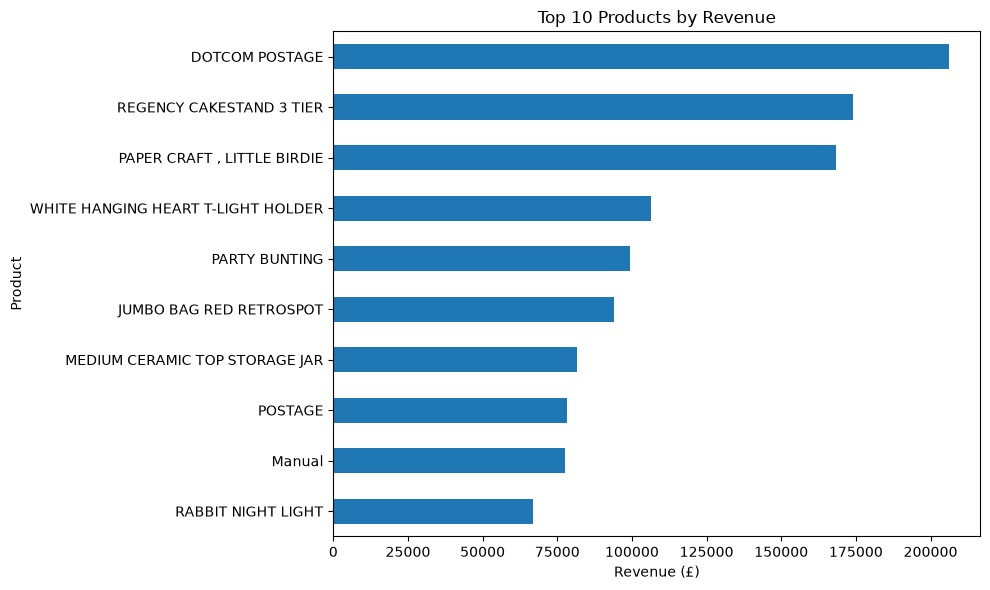

In [72]:
top_products = (
    df_sales.groupby('Description')['TotalPrice']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
top_products.plot(kind='barh')

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Product')

plt.tight_layout()
plt.show()

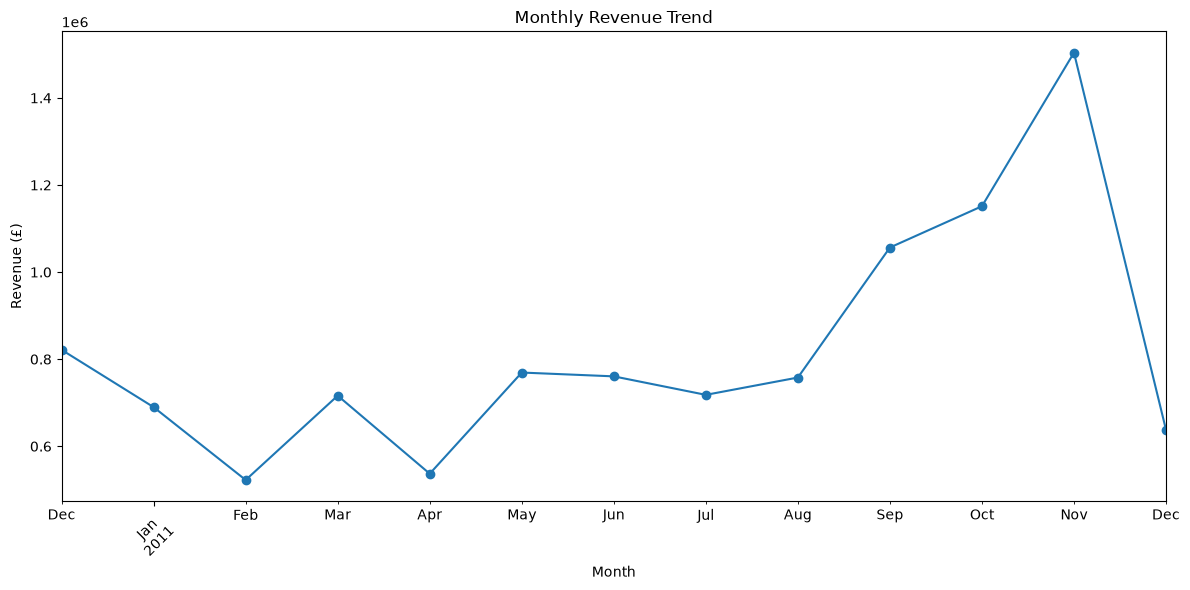

In [73]:
monthly_revenue = df_sales.copy()

monthly_revenue['YearMonth'] = (
    monthly_revenue['InvoiceDate'].dt.to_period('M')
)

monthly_revenue = monthly_revenue.groupby('YearMonth')['TotalPrice'].sum()

plt.figure(figsize=(12, 6))
monthly_revenue.plot(kind='line', marker='o')

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

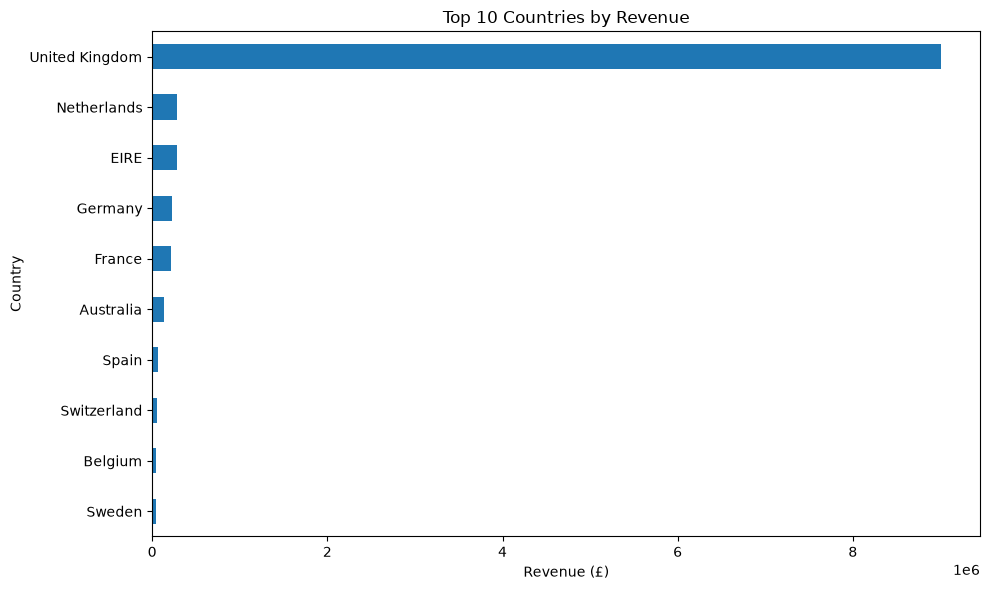

In [74]:
country_revenue = (
    df_sales.groupby('Country')['TotalPrice']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
country_revenue.plot(kind='barh')

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Country')

plt.tight_layout()
plt.show()


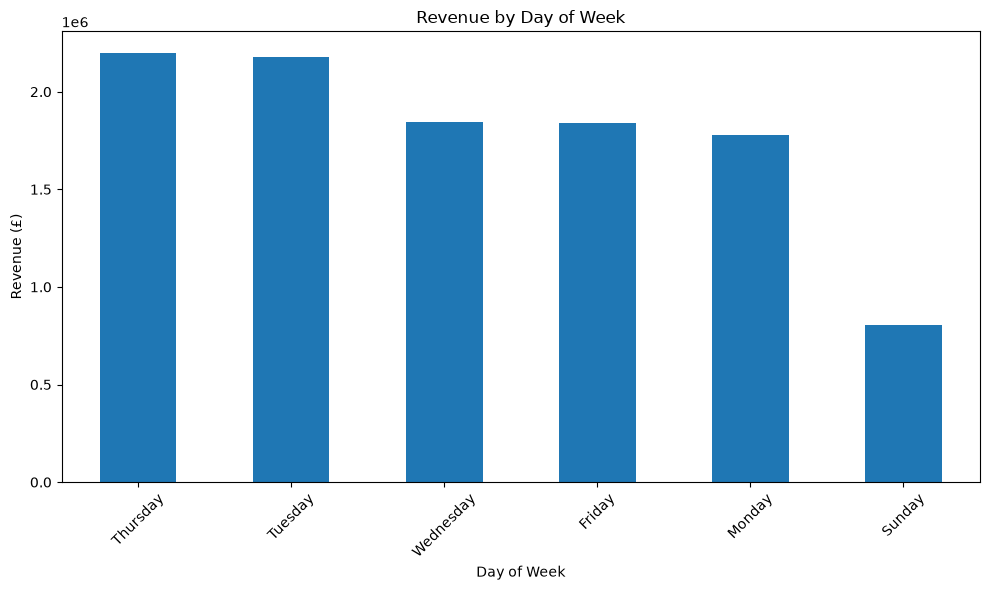

In [75]:
day_revenue = (
    df_sales.groupby('DayOfWeek')['TotalPrice']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
day_revenue.plot(kind='bar')

plt.title('Revenue by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

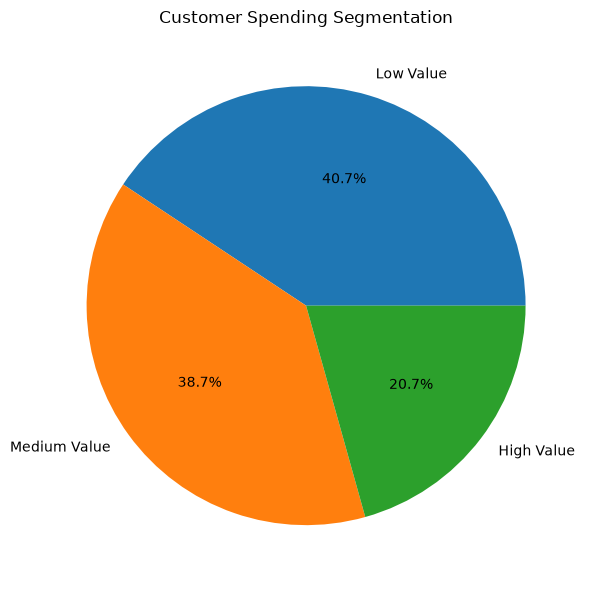

In [76]:
segment_counts = customer_segments.value_counts()

plt.figure(figsize=(8, 6))
segment_counts.plot(kind='pie', autopct='%1.1f%%')

plt.title('Customer Spending Segmentation')
plt.ylabel('')

plt.tight_layout()
plt.show()

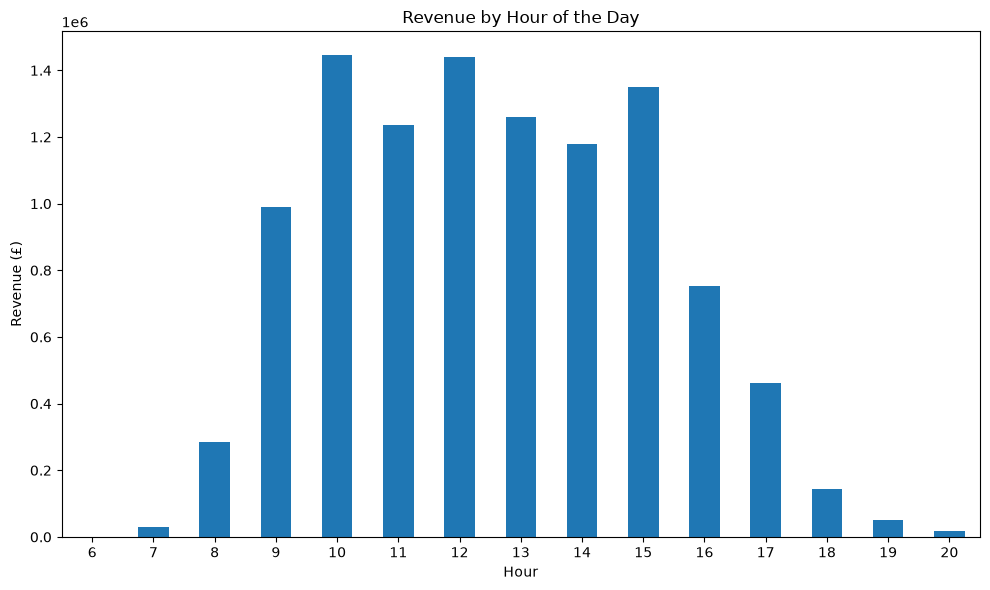

In [77]:
hourly_revenue = (
    df_sales.groupby('Hour')['TotalPrice']
    .sum()
)

plt.figure(figsize=(10, 6))
hourly_revenue.plot(kind='bar')

plt.title('Revenue by Hour of the Day')
plt.xlabel('Hour')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Top 10 Products by Revenue

- DOTCOM POSTAGE generated the highest revenue (£206,248.77).
- REGENCY CAKESTAND 3 TIER ranked second (£174,156.54).
- PAPER CRAFT, LITTLE BIRDIE ranked third (£168,469.60).
- Postage-related items and popular gift products contributed significantly to revenue.

### Monthly Revenue Trend

- November 2011 recorded the highest monthly revenue (£1,503,866.78).
- October 2011 ranked second (£1,151,263.73).
- September 2011 generated £1,056,435.19.
- February 2011 recorded the lowest monthly revenue (£522,545.56).
- Revenue increased significantly between September and November 2011.

### Revenue by Country

- The United Kingdom generated the highest revenue (£9,001,744.09).
- The Netherlands ranked second (£285,446.34).
- Ireland (EIRE) ranked third (£283,140.52).
- Germany and France were also among the top five revenue-generating countries.
- The United Kingdom contributed the largest share of total sales revenue.

### Revenue by Day of Week

- Thursday recorded the highest revenue (£2,199,292.57).
- Tuesday ranked second (£2,175,700.51).
- Sunday recorded the lowest revenue (£806,790.78).
- Sales revenue was strongest on weekdays compared with Sunday.
- No Saturday transactions were recorded in the dataset.

### Customer Spending Segmentation

- 1,765 customers were classified as Low Value customers.
- 1,677 customers were classified as Medium Value customers.
- 896 customers were classified as High Value customers.
- Low Value customers represented the largest customer segment.
- High Value customers represented the smallest segment.
- Customer segments were defined based on total spending.

### Revenue by Hour of the Day

- 10 AM recorded the highest revenue (£1,444,814.77).
- 12 PM ranked second (£1,439,324.66).
- 3 PM ranked third (£1,350,333.31).
- Sales activity was strongest during late morning and afternoon hours.
- Understanding peak sales hours can help businesses plan their operations.